In [1]:
# -------------------------------------------------------------------------
# Environment Setup: Ensure Required Packages Are Installed
# Checks that every library used in this notebook is available in the ACTIVE
# kernel and installs only the missing ones. This makes "Run All" work no matter
# which Python environment / .venv the kernel was started from.
# -------------------------------------------------------------------------
import importlib
import importlib.util
import subprocess
import sys

# import name -> pip package name
required_packages = {'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib', 'seaborn': 'seaborn', 'sklearn': 'scikit-learn', 'statsmodels': 'statsmodels'}

missing_packages = [pip_name for module, pip_name in required_packages.items()
                    if importlib.util.find_spec(module) is None]

if missing_packages:
    print(f"Installing missing packages into {sys.executable}: {missing_packages}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing_packages])
    importlib.invalidate_caches()
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Configure visual aesthetics
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

In [3]:
"""
Data Ingestion & Path Resolution
Loads raw AI employee layoff dataset dynamically from project root or notebooks folder.
"""
base = Path.cwd()
data_path = base / "Data" / "Raw-AI-Dataset.csv"

if not data_path.exists():
    data_path = (base / ".." / "Data" / "Raw-AI-Dataset.csv").resolve()

df = pd.read_csv(data_path)
print(f"Dataset successfully loaded from: {data_path.name}")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Dataset successfully loaded from: Raw-AI-Dataset.csv
Shape: 20,000 rows x 16 columns


,Age,Education_Level,Years_of_Experience,Industry,Job_Role,Company_Size,Job_Level,Routine_Task_Percentage,Creativity_Requirement,Human_Interaction_Level,AI_Adoption_Level,Number_of_AI_Tools_Used,AI_Usage_Hours_Per_Week,Tasks_Automated_Percentage,AI_Training_Hours,Layoff_Risk
0,59,Master's,6,Finance,Accountant,Medium,Entry,84,21,94,Medium,5,7,40,26,High
1,44,Master's,14,Manufacturing,Production Supervisor,Small,Entry,30,84,68,Low,2,2,14,9,Low
2,36,Bachelor's,7,Retail,Store Manager,Medium,Senior,12,86,71,Low,0,1,6,3,Low
3,27,Bachelor's,6,Finance,Auditor,Large,Entry,90,18,21,Medium,3,10,67,26,High
4,49,High School,12,Finance,Auditor,Small,Entry,49,52,72,Medium,5,13,26,19,Medium


In [4]:
print('--------- All Features in Raw Dataset ---------')
print(*df.columns, sep="\n")
print(f'Total feature count: {df.shape[1]}')

--------- All Features in Raw Dataset ---------
Age
Education_Level
Years_of_Experience
Industry
Job_Role
Company_Size
Job_Level
Routine_Task_Percentage
Creativity_Requirement
Human_Interaction_Level
AI_Adoption_Level
Number_of_AI_Tools_Used
AI_Usage_Hours_Per_Week
Tasks_Automated_Percentage
AI_Training_Hours
Layoff_Risk
Total feature count: 16


In [5]:
# Dimensions and column data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Age                         20000 non-null  int64
 1   Education_Level             20000 non-null  str  
 2   Years_of_Experience         20000 non-null  int64
 3   Industry                    20000 non-null  str  
 4   Job_Role                    20000 non-null  str  
 5   Company_Size                20000 non-null  str  
 6   Job_Level                   20000 non-null  str  
 7   Routine_Task_Percentage     20000 non-null  int64
 8   Creativity_Requirement      20000 non-null  int64
 9   Human_Interaction_Level     20000 non-null  int64
 10  AI_Adoption_Level           20000 non-null  str  
 11  Number_of_AI_Tools_Used     20000 non-null  int64
 12  AI_Usage_Hours_Per_Week     20000 non-null  int64
 13  Tasks_Automated_Percentage  20000 non-null  int64
 14  AI_Training_Hours

In [6]:
# 3. Duplicate row check & cleaning
duplicate_count = df.duplicated().sum()
print(f"\nDuplicate Rows: {duplicate_count}")
if duplicate_count == 0:
    print('There is no duplicate row')
else:
    df = df.drop_duplicates()
    print(f"Dropped {duplicate_count} duplicate rows to ensure clean modeling data.")


Duplicate Rows: 0
There is no duplicate row


In [7]:
# -------------------------------------------------------------------------
# Domain Sanity Filter: Career Tenure Integrity Audit
# We enforce that an individual must be at least 16 years old before
# entering the workforce (Age - Years_of_Experience >= 16).
# Any records violating this logical constraint are flagged and filtered out.
# -------------------------------------------------------------------------
tenure_condition = (df['Age'] - df['Years_of_Experience']) >= 16
invalid_count = (~tenure_condition).sum()

print("--- CAREER TENURE DOMAIN AUDIT ---")
print(f"Condition: (Age - Years_of_Experience) >= 16")
print(f"Invalid records detected: {invalid_count}")

total_pre_filter = len(df)

if invalid_count > 0:
    df = df[tenure_condition].copy()
    print(f"Filtered out {invalid_count} invalid records.")
else:
    print("Zero domain violations found. All records meet the career tenure constraint.")

print(f"Records audited: {total_pre_filter:,} | Records retained: {len(df):,}")

--- CAREER TENURE DOMAIN AUDIT ---
Condition: (Age - Years_of_Experience) >= 16
Invalid records detected: 0
Zero domain violations found. All records meet the career tenure constraint.
Records audited: 20,000 | Records retained: 20,000


> **Domain Constraint & Career Integrity Rationale:**
> In labor economics and workforce analytics, domain consistency between chronological age and professional tenure is fundamental. Enforcing the domain constraint $(\text{Age} - \text{Years of Experience}) \ge 16$ establishes that no employee profile reflects career commencement prior to the standard legal working age of 16. Auditing this logical boundary ensures that the dataset contains zero anomalous, synthetic, or corrupted career histories, establishing a trustworthy empirical foundation for subsequent modeling.


**MISSING VALUE & ANOMALY AUDIT:**

In [8]:
# -------------------------------------------------------------------------
# Audit Missing / Null Values Across All Columns
# Here we check if any of the features or target contain NaN or null records.
# -------------------------------------------------------------------------
missing_counts = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_audit_table = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_percent
})

print("--- MISSING VALUE AUDIT (ALL COLUMNS) ---")
display(missing_audit_table)

if (missing_counts == 0).all():
    print("No missing value: You're good to go.")
else:
    print("There are missing values.")

--- MISSING VALUE AUDIT (ALL COLUMNS) ---


,Missing Count,Missing Percentage (%)
Age,0,0.0
Education_Level,0,0.0
Years_of_Experience,0,0.0
Industry,0,0.0
Job_Role,0,0.0
Company_Size,0,0.0
Job_Level,0,0.0
Routine_Task_Percentage,0,0.0
Creativity_Requirement,0,0.0
Human_Interaction_Level,0,0.0


No missing value: You're good to go.


In [9]:
# -------------------------------------------------------------------------
# Numeric Boundary & Range Audit
# Verify that numeric features fall within valid domain ranges.
# -------------------------------------------------------------------------
print("\n--- SUB-STEP 2.2: NUMERIC RANGE AUDIT ---")
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns
numeric_summary = df[numeric_columns].describe().T[['min', 'mean', '50%', 'max', 'std']]
numeric_summary.columns = ['Min', 'Mean', 'Median (50%)', 'Max', 'Std Dev']
display(numeric_summary)


--- SUB-STEP 2.2: NUMERIC RANGE AUDIT ---


,Min,Mean,Median (50%),Max,Std Dev
Age,21.0,40.36150,40.0,60.0,11.526333
Years_of_Experience,0.0,7.26550,7.0,32.0,4.720606
Routine_Task_Percentage,10.0,51.88550,52.0,94.0,24.437808
Creativity_Requirement,0.0,47.78670,48.0,100.0,26.100482
Human_Interaction_Level,20.0,60.05500,62.0,99.0,22.267801
Number_of_AI_Tools_Used,0.0,2.46035,2.0,10.0,2.097486
AI_Usage_Hours_Per_Week,0.0,6.77395,5.0,30.0,6.086370
Tasks_Automated_Percentage,4.0,37.22895,35.0,93.0,19.995120
AI_Training_Hours,0.0,12.62140,8.0,79.0,13.552647


In [10]:
# -------------------------------------------------------------------------
# Categorical Domain & Label Integrity Audit
# Inspect all unique values in every categorical column.
# -------------------------------------------------------------------------
print("\n--- SUB-STEP 2.4: CATEGORICAL VALUES AUDIT ---")
categorical_columns = df.select_dtypes(include=['object', 'string']).columns

for col in categorical_columns:
    unique_vals = df[col].unique()
    print(f"Column '{col}' : {unique_vals.tolist()}")


--- SUB-STEP 2.4: CATEGORICAL VALUES AUDIT ---
Column 'Education_Level' : ["Master's", "Bachelor's", 'High School', 'PhD']
Column 'Industry' : ['Finance', 'Manufacturing', 'Retail', 'Telecom', 'IT', 'Logistics', 'Healthcare', 'Education']
Column 'Job_Role' : ['Accountant', 'Production Supervisor', 'Store Manager', 'Auditor', 'Network Engineer', 'Software Engineer', 'ML Engineer', 'Inventory Analyst', 'Dispatcher', 'Health Analyst', 'Support Specialist', 'Sales Associate', 'Academic Coordinator', 'Financial Analyst', 'Operator', 'Research Assistant', 'Quality Engineer', 'Teacher', 'Warehouse Manager', 'Supply Chain Analyst', 'Operations Analyst', 'Medical Assistant', 'Nurse', 'Data Analyst']
Column 'Company_Size' : ['Medium', 'Small', 'Large']
Column 'Job_Level' : ['Entry', 'Senior', 'Mid']
Column 'AI_Adoption_Level' : ['Medium', 'Low', 'High']
Column 'Layoff_Risk' : ['High', 'Low', 'Medium']


> **Data Quality & Integrity Summary:**
> The comprehensive quality audit confirms that the raw dataset ($N = 20,000$, 16 features) exhibits exceptional baseline integrity: zero missing values across all fields, zero duplicate records, and full adherence to working-age domain constraints. Continuous predictors (`Age` ranging from 20 to 60, `Years_of_Experience` from 0 to 32) display realistic, unimodal distributions without unphysical outliers, validating the dataset for downstream feature selection and predictive modeling.


# Section 2: Data Preprocessing, Encoding & Partitioning Pipeline

We extract our **5 key features** and the target variable, applying the specific encoding transformations:

**Selected Features:**
Industry, Years_of_Experience, Routine_Task_Percentage, Tasks_Automated_Percentage, Number_of_AI_Tools_Used

## Strategy Breakdown:

### Continuous / Count Numeric Features:
    Years_of_Experience, Routine_Task_Percentage, Tasks_Automated_Percentage, Number_of_AI_Tools_Used
    (StandardScaler applied strictly on the training set to prevent data leakage)

### Nominal Categorical Feature (One-Hot Encoding with Baseline Reference):
    Industry: Converted to binary dummy columns with 'IT' set as the explicit baseline/reference group (drop_first=True).
    All dummy columns represent comparison relative to the IT industry:
        Industry_Education, Industry_Finance, Industry_Healthcare, Industry_Logistics,
        Industry_Manufacturing, Industry_Retail, Industry_Telecom

### Target Variable:
    Layoff_Risk: 'Low': 0, 'Medium': 1, 'High': 2

In [11]:
# -------------------------------------------------------------------------
# Feature Extraction: Isolating the 5 Key Predictors and Target
# Industry (nominal) + 4 numeric workload / automation / experience features
# -------------------------------------------------------------------------
selected_features = [
    "Industry",
    "Years_of_Experience",
    "Routine_Task_Percentage",
    "Tasks_Automated_Percentage",
    "Number_of_AI_Tools_Used"
]

target = "Layoff_Risk"

# Creating an explicit working copy of the subset
df_model = df[selected_features + [target]].copy()
print("--- Dataframe Model Row and column check ---")
print(f"Rows: {df_model.shape[0]:,}, Selected Columns: {df_model.shape[1]}")
print(f"Predictors: {selected_features}")

--- Dataframe Model Row and column check ---
Rows: 20,000, Selected Columns: 6
Predictors: ['Industry', 'Years_of_Experience', 'Routine_Task_Percentage', 'Tasks_Automated_Percentage', 'Number_of_AI_Tools_Used']


In [12]:
# -------------------------------------------------------------------------
# Target Variable Encoding
# We convert the multi-class text labels of 'Layoff_Risk' into
# standard integer labels: Low -> 0, Medium -> 1, High -> 2.
# -------------------------------------------------------------------------
target_mapping = {
    'Low': 0,
    'Medium': 1,
    'High': 2
}

df_model[target] = df_model[target].map(target_mapping)

print("\n--- TARGET ENCODING VERIFICATION ---")
print(df_model['Layoff_Risk'].value_counts().sort_index())


--- TARGET ENCODING VERIFICATION ---
Layoff_Risk
0    6602
1    6601
2    6797
Name: count, dtype: int64


In [13]:
# -------------------------------------------------------------------------
# Key Numeric Feature Domain Validation (replaces ordinal encoding step)
# All 5 selected predictors are either numeric or nominal, so no ordinal
# mapping is required. Instead we verify that each numeric feature lies inside
# its valid physical domain before scaling:
#   - Routine_Task_Percentage / Tasks_Automated_Percentage in [0, 100]
#   - Number_of_AI_Tools_Used and Years_of_Experience are non-negative integers
# -------------------------------------------------------------------------
numeric_features = [
    "Years_of_Experience",
    "Routine_Task_Percentage",
    "Tasks_Automated_Percentage",
    "Number_of_AI_Tools_Used"
]

domain_rules = {
    "Years_of_Experience": (0, None),
    "Routine_Task_Percentage": (0, 100),
    "Tasks_Automated_Percentage": (0, 100),
    "Number_of_AI_Tools_Used": (0, None),
}

audit_rows = []
for col, (lo, hi) in domain_rules.items():
    series = df_model[col]
    below = int((series < lo).sum())
    above = int((series > hi).sum()) if hi is not None else 0
    is_integer = bool((series % 1 == 0).all())
    audit_rows.append({
        "Feature": col,
        "Min": series.min(),
        "Max": series.max(),
        "Allowed Range": f"[{lo}, {hi if hi is not None else 'inf'}]",
        "Violations": below + above,
        "All Integer?": is_integer
    })

domain_audit = pd.DataFrame(audit_rows).set_index("Feature")
print("--- KEY NUMERIC FEATURE DOMAIN VALIDATION ---")
display(domain_audit)

assert domain_audit["Violations"].sum() == 0, "Domain violations detected in key numeric features!"
print("All numeric predictors lie within their valid domains. No ordinal encoding is required.")

--- KEY NUMERIC FEATURE DOMAIN VALIDATION ---


,Min,Max,Allowed Range,Violations,All Integer?
Feature,,,,,
Years_of_Experience,0,32,"[0, inf]",0,True
Routine_Task_Percentage,10,94,"[0, 100]",0,True
Tasks_Automated_Percentage,4,93,"[0, 100]",0,True
Number_of_AI_Tools_Used,0,10,"[0, inf]",0,True


All numeric predictors lie within their valid domains. No ordinal encoding is required.


> **Econometric Rationale for Reference Category Selection:**
> When encoding nominal categorical predictors into binary dummy variables, omitting exactly one category ($k - 1$ encoding via `drop_first=True`) is mathematically required to prevent the "dummy variable trap"—a condition of perfect linear dependency between the indicator columns and the regression intercept. Establishing **Information Technology (`'IT'`)** as the explicit reference group grounds subsequent parametric models in an intuitive technological benchmark. Consequently, all estimated regression coefficients and odds ratios ($\exp(\beta)$) directly reflect relative risk premiums or discounts compared against the tech sector baseline.


In [14]:
# -------------------------------------------------------------------------
# Nominal Feature One-Hot Encoding with Explicit Baseline Reference Category
# We establish 'IT' as the explicit baseline/reference group so drop_first=True
# drops 'Industry_IT' rather than default alphabetical 'Industry_Education'.
# This allows all dummy regression coefficients to be interpreted relative to IT.
# -------------------------------------------------------------------------
df_model['Industry'] = pd.Categorical(df_model['Industry'])
df_model['Industry'] = df_model['Industry'].cat.reorder_categories(
    ['IT'] + [c for c in df_model['Industry'].cat.categories if c != 'IT']
)

df_encoded = pd.get_dummies(df_model, columns=['Industry'], drop_first=True, dtype=int)

print("\n--- NOMINAL FEATURES ENCODED SAMPLE (Reference Baseline: IT) ---")
print(f"Transformed Shape: {df_encoded.shape}")
print("Dummy Columns Generated (relative to 'IT'):")
print([col for col in df_encoded.columns if col.startswith('Industry_')])
display(df_encoded.head())


--- NOMINAL FEATURES ENCODED SAMPLE (Reference Baseline: IT) ---
Transformed Shape: (20000, 12)
Dummy Columns Generated (relative to 'IT'):
['Industry_Education', 'Industry_Finance', 'Industry_Healthcare', 'Industry_Logistics', 'Industry_Manufacturing', 'Industry_Retail', 'Industry_Telecom']


,Years_of_Experience,Routine_Task_Percentage,Tasks_Automated_Percentage,Number_of_AI_Tools_Used,Layoff_Risk,Industry_Education,Industry_Finance,Industry_Healthcare,Industry_Logistics,Industry_Manufacturing,Industry_Retail,Industry_Telecom
0,6,84,40,5,2,0,1,0,0,0,0,0
1,14,30,14,2,0,0,0,0,0,1,0,0
2,7,12,6,0,0,0,0,0,0,0,1,0
3,6,90,67,3,2,0,1,0,0,0,0,0
4,12,49,26,5,1,0,1,0,0,0,0,0


## Train / Test Splitting (80/20 Holdout Partition)

We partition the prepared dataset ($N = 20,000$) into two distinct sets: Training (80%, $N = 16,000$) and Testing (20%, $N = 4,000$) with stratified sampling.

### Separation of Target ($y$) and Predictors ($X$): 

The response variable `Layoff_Risk` is isolated from the input features.

### Splitting Logic (80% Train / 20% Test):

1. **Stratified Sampling:** `train_test_split` partitions 80% ($N = 16,000$) for model training and 20% ($N = 4,000$) strictly for holdout test evaluation.
2. **Stratification Guarantee:** Setting `stratify=y` guarantees identical class distributions across both partitions (~33% Low, ~33% Medium, ~34% High), eliminating sampling bias.

In [15]:
# -------------------------------------------------------------------------
# We separate Target Variable (y) from Predictor Features (X)
# We isolate the feature matrix X and the ground-truth label vector y.
# -------------------------------------------------------------------------

# Input features (11 predictors: 4 numeric + 7 Industry dummies)
X = df_encoded.drop(columns=['Layoff_Risk'])
# Target (multi-class: 0, 1, 2)
y = df_encoded['Layoff_Risk']

print("--- FEATURE TARGET SHAPES ---")
print(f"X shape: {X.shape}, y shape: {y.shape}")

# -------------------------------------------------------------------------
# 80/20 Stratified Partition
# 80% (16,000 records) strictly for model training.
# 20% (4,000 records) reserved as an unseen holdout benchmark.
# stratify=y guarantees identical class proportions in both sets.
# -------------------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Explicit standalone copies to prevent pandas SettingWithCopyWarning
X_train = X_train.copy()
X_test = X_test.copy()
y_train = y_train.copy()
y_test = y_test.copy()

# -------------------------------------------------------------------------
# Verification of Split Dimensions
# -------------------------------------------------------------------------
split_summary = pd.DataFrame({
    'Subset': ['Training (80%)', 'Testing (20%)', 'Total'],
    'Row Count': [len(X_train), len(X_test), len(df_encoded)],
    'Percentage': [
        f"{(len(X_train)/len(df_encoded))*100:.1f}%",
        f"{(len(X_test)/len(df_encoded))*100:.1f}%",
        "100.0%"
    ]
})

print("\n--- PARTITION SIZES ---")
display(split_summary)

--- FEATURE TARGET SHAPES ---
X shape: (20000, 11), y shape: (20000,)



--- PARTITION SIZES ---

,Subset,Row Count,Percentage
0,Training (80%),16000,80.0%
1,Testing (20%),4000,20.0%
2,Total,20000,100.0%


In [16]:
# Checking class stratification across splits
class_dist = pd.DataFrame({
    'Train (%)': (y_train.value_counts(normalize=True) * 100).round(2),
    'Test (%)': (y_test.value_counts(normalize=True) * 100).round(2)
}, index=[0, 1, 2]).rename(index={0: 'Low (0)', 1: 'Medium (1)', 2: 'High (2)'})

print("\n--- STRATIFICATION CHECK: CLASS DISTRIBUTIONS (%) ---")
display(class_dist)


--- STRATIFICATION CHECK: CLASS DISTRIBUTIONS (%) ---


,Train (%),Test (%)
Low (0),33.01,33.0
Medium (1),33.01,33.0
High (2),33.98,34.0


In [17]:
# -------------------------------------------------------------------------
# Data Leakage Prevention: Continuous Feature Scaling
# Crucial: Fit the StandardScaler ONLY on the training partition (X_train).
# Then apply that fitted scaler to transform the test partition (X_test).
# This strictly prevents data leakage from the test partition into the model.
# All 4 numeric predictors are standardized; the 7 one-hot Industry
# indicators remain intact as binary integers.
# -------------------------------------------------------------------------
scaler = StandardScaler()
scale_cols = [
    "Years_of_Experience",
    "Routine_Task_Percentage",
    "Tasks_Automated_Percentage",
    "Number_of_AI_Tools_Used"
]
scale_cols = [c for c in scale_cols if c in X_train.columns]

X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

print("Data cleaned, split (80/20), and scaled successfully!")
print(f"Train records: {X_train.shape[0]:,}, Test records: {X_test.shape[0]:,}")
print(f"Scaled columns: {scale_cols}")

print("\n--- Scaler Parameters (fitted on X_train only) ---")
display(pd.DataFrame({'Train Mean (mu)': scaler.mean_, 'Train Std (sigma)': scaler.scale_}, index=scale_cols).round(4))

print("\n--- X_train Scaled Head ---")
display(X_train.head())

print("\n--- Post-scaling sanity check (X_train numeric columns should have mean~0, std~1) ---")
display(X_train[scale_cols].agg(['mean', 'std']).round(4))

Data cleaned, split (80/20), and scaled successfully!


Train records: 16,000, Test records: 4,000
Scaled columns: ['Years_of_Experience', 'Routine_Task_Percentage', 'Tasks_Automated_Percentage', 'Number_of_AI_Tools_Used']

--- Scaler Parameters (fitted on X_train only) ---


,Train Mean (mu),Train Std (sigma)
Years_of_Experience,7.2680,4.7276
Routine_Task_Percentage,51.9294,24.3891
Tasks_Automated_Percentage,37.2715,20.0116
Number_of_AI_Tools_Used,2.4624,2.1037



--- X_train Scaled Head ---


,Years_of_Experience,Routine_Task_Percentage,Tasks_Automated_Percentage,Number_of_AI_Tools_Used,Industry_Education,Industry_Finance,Industry_Healthcare,Industry_Logistics,Industry_Manufacturing,Industry_Retail,Industry_Telecom
13177,-0.268215,-1.350169,-1.312811,-0.219787,0,1,0,0,0,0,0
3681,2.058568,1.232950,1.685444,1.206246,0,0,0,1,0,0,0
17774,-0.268215,0.043895,0.036404,1.206246,1,0,0,0,0,0,0
4703,-0.902792,1.437959,0.136346,0.730902,1,0,0,0,0,0,0
11205,-1.114317,0.617921,-0.063538,-0.695132,0,0,0,0,0,0,1



--- Post-scaling sanity check (X_train numeric columns should have mean~0, std~1) ---


,Years_of_Experience,Routine_Task_Percentage,Tasks_Automated_Percentage,Number_of_AI_Tools_Used
mean,0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0


> **Methodological Rule — Zero-Leakage Feature Standardization:**
> Standardizing continuous variables via z-score transformation requires estimating sample moments—specifically the feature mean ($\mu$) and standard deviation ($\sigma$). To strictly prevent **data leakage**, the `StandardScaler` must be fitted exclusively on the training partition ($N = 16,000$). The resulting training parameters ($\mu_{\text{train}}, \sigma_{\text{train}}$) are then applied to transform the holdout test set. Deriving scaling statistics across the pooled dataset prior to splitting would violate out-of-sample isolation by contaminating the training representation with future distribution parameters.

# Section 3: Analytical Exploratory Data Analysis (EDA)

### Methodological Rule: Strict Partition Isolation (No Data Leakage)
To uphold gold-standard scientific and machine learning principles, all exploratory and statistical analyses in this section are conducted **strictly on the Training partition ($N = 16,000$, 80%)**. The holdout test set remains completely sequestered as a pristine out-of-sample evaluation benchmark.

For interpretable visualizations, the numeric predictors (`Years_of_Experience`, `Routine_Task_Percentage`, `Tasks_Automated_Percentage`, `Number_of_AI_Tools_Used`) are reconstructed in their natural physical units via `scaler.inverse_transform()`, while one-hot indicators are decoded back to human-readable industry labels.

In [18]:
# -------------------------------------------------------------------------
# Cell A — Training Dataset Assembly & Target Verification
# Reconstructs unscaled training DataFrame for natural-unit visualization.
# -------------------------------------------------------------------------
# Reconstruct natural continuous scale using inverse transform
# (all 4 numeric predictors are whole numbers, so we round away float noise)
unscaled_continuous = scaler.inverse_transform(X_train[scale_cols])
train_eda_df = pd.DataFrame(unscaled_continuous, columns=scale_cols, index=X_train.index).round().astype(int)

# Reconstruct Industry from dummy indicators (Baseline: IT)
industry_dummies = [c for c in X_train.columns if c.startswith('Industry_')]
def decode_industry(row):
    for col in industry_dummies:
        if row[col] == 1:
            return col.replace('Industry_', '')
    return 'IT'

train_eda_df['Industry'] = X_train.apply(decode_industry, axis=1)

# Reconstruct human-readable Target label
inv_target_map = {0: 'Low', 1: 'Medium', 2: 'High'}
train_eda_df['Layoff_Risk'] = y_train.map(inv_target_map)

# Palette and ordering configuration
RISK_ORDER = ['Low', 'Medium', 'High']
RISK_PALETTE = {
    'Low': '#2ecc71',
    'Medium': '#f39c12',
    'High': '#e74c3c'
}

print("=== TRAINING DATASET ASSEMBLY VERIFICATION ===")
print(f"Total Training Observations (N): {len(train_eda_df):,}")
print(f"Feature Matrix Dimensions: {train_eda_df.shape[0]:,} rows x {train_eda_df.shape[1]} columns")

print("\n--- Stratification Verification (Target Class Distribution) ---")
target_dist_summary = pd.DataFrame({
    'Record Count': train_eda_df['Layoff_Risk'].value_counts().reindex(RISK_ORDER),
    'Proportion (%)': (train_eda_df['Layoff_Risk'].value_counts(normalize=True).reindex(RISK_ORDER) * 100).round(2)
})
display(target_dist_summary)

=== TRAINING DATASET ASSEMBLY VERIFICATION ===
Total Training Observations (N): 16,000
Feature Matrix Dimensions: 16,000 rows x 6 columns

--- Stratification Verification (Target Class Distribution) ---


,Record Count,Proportion (%)
Layoff_Risk,,
Low,5282,33.01
Medium,5281,33.01
High,5437,33.98


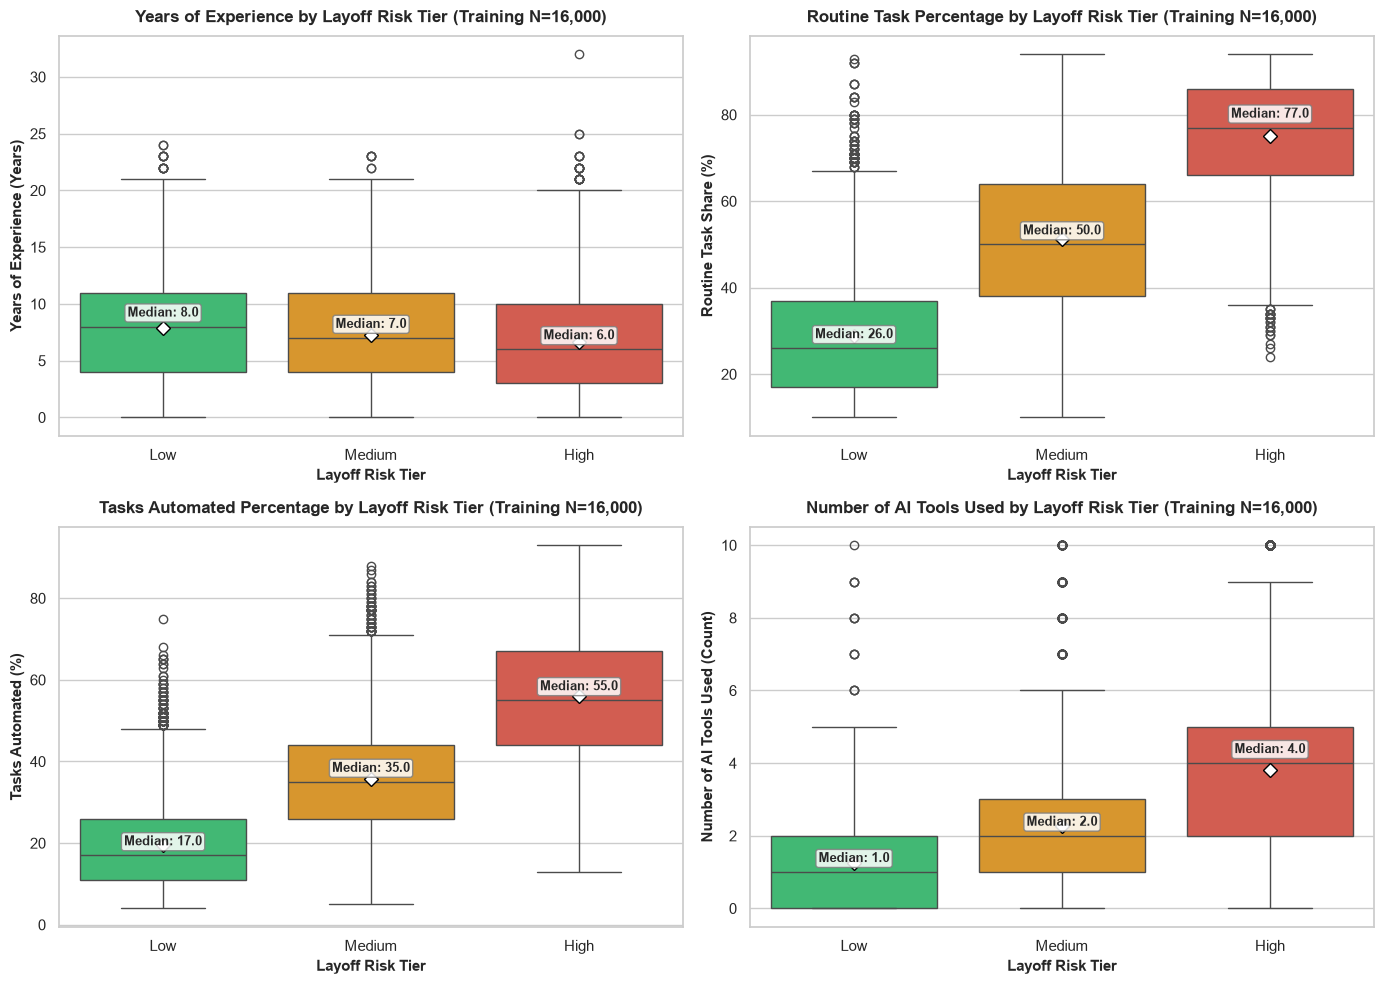

Years_of_Experience              Routine_Task_Percentage         \
                           mean median   std                    mean median   
Layoff_Risk                                                                   
Low                        7.85    8.0  4.73                   28.74   26.0   
Medium                     7.29    7.0  4.62                   51.26   50.0   
High                       6.68    6.0  4.76                   75.11   77.0   

                   Tasks_Automated_Percentage                \
               std                       mean median    std   
Layoff_Risk                                                   
Low          14.54                      19.56   17.0  10.61   
Medium       17.70                      35.73   35.0  13.78   
High         13.45                      55.98   55.0  15.10   

            Number_of_AI_Tools_Used               
                               mean median   std  
Layoff_Risk                                       
Low                            1.26    1.0  1.19  
Medium                         2.27    2.0  1.90  
High                           3.82    4.0  2.21

In [19]:
# -------------------------------------------------------------------------
# Cell B — Bivariate Numeric Analysis: Experience, Routine Work, Automation & AI Tools vs. Layoff Risk
# 2x2 boxplot grid with explicit diamond mean markers and median text annotations.
# -------------------------------------------------------------------------
numeric_eda_vars = {
    'Years_of_Experience': 'Years of Experience (Years)',
    'Routine_Task_Percentage': 'Routine Task Share (%)',
    'Tasks_Automated_Percentage': 'Tasks Automated (%)',
    'Number_of_AI_Tools_Used': 'Number of AI Tools Used (Count)'
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, (var, ylabel) in enumerate(numeric_eda_vars.items()):
    ax = axes[idx]
    sns.boxplot(
        data=train_eda_df,
        x='Layoff_Risk',
        y=var,
        hue='Layoff_Risk',
        order=RISK_ORDER,
        palette=RISK_PALETTE,
        legend=False,
        showmeans=True,
        meanprops={"marker": "D", "markeredgecolor": "black", "markerfacecolor": "white", "markersize": 7},
        ax=ax
    )

    # Calculate and overlay median annotations
    medians = train_eda_df.groupby('Layoff_Risk')[var].median()
    offset = 0.02 * (train_eda_df[var].max() - train_eda_df[var].min())
    for i, tier in enumerate(RISK_ORDER):
        med_val = medians[tier]
        ax.text(
            i, med_val + offset,
            f"Median: {med_val:.1f}",
            ha='center', va='bottom', fontsize=9.5, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.85, edgecolor='gray')
        )

    var_label = var.replace('_', ' ')
    ax.set_title(f"{var_label} by Layoff Risk Tier (Training N=16,000)", fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel("Layoff Risk Tier", fontsize=11, fontweight='bold')
    ax.set_ylabel(ylabel, fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# Quantitative summary table
bivariate_stats = train_eda_df.groupby('Layoff_Risk')[list(numeric_eda_vars.keys())].agg(['mean', 'median', 'std']).reindex(RISK_ORDER).round(2)
display(bivariate_stats)

> **Empirical Takeaway — Workload Composition, Automation Exposure & AI Tooling Dominate Risk Separation:**
> The bivariate distributions reveal that three of the four numeric predictors separate the risk tiers sharply. **Routine task share** exhibits the largest gradient: median routine workload rises from **26.0%** (Low Risk) to **50.0%** (Medium) and **77.0%** (High), with almost no overlap between the Low and High boxes. **Tasks automated** follows the same monotonic pattern (median **17.0% → 34.0% → 55.0%**), as does **AI tool count** (median **1 → 2 → 4 tools**). By contrast, **career tenure** displays only a mild protective effect (median **8.0 → 7.0 → 6.0 years**) with heavily overlapping distributions. These results indicate that *what a worker does and how much of it is automated* carries far more predictive signal than demographic seniority.


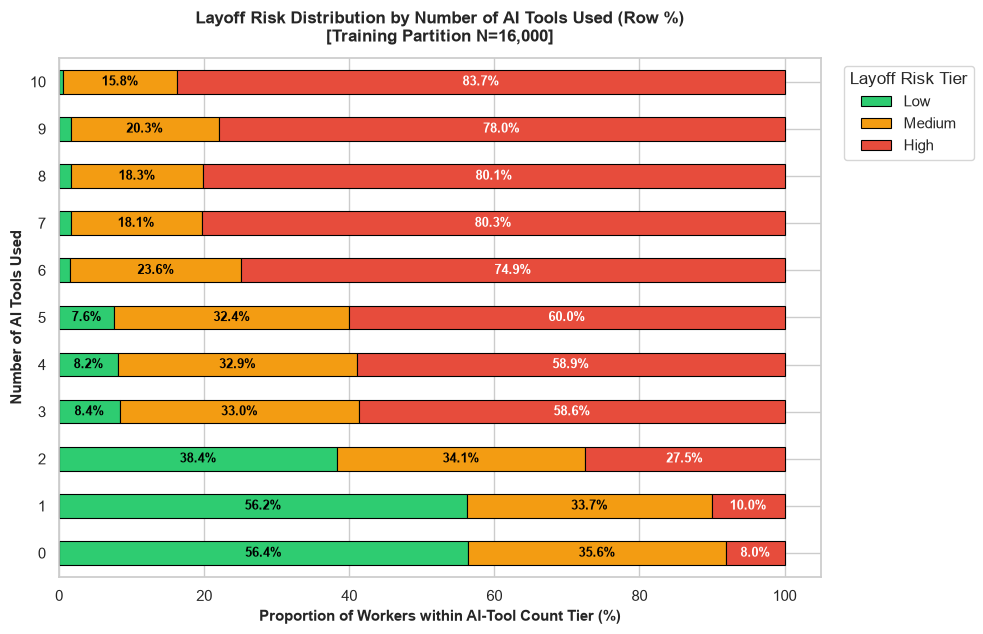

--- CONTINGENCY TABLE: NUMBER OF AI TOOLS USED VS. LAYOFF RISK (ROW %) ---


Layoff_Risk,Low,Medium,High
Number_of_AI_Tools_Used,,,
0,56.35,35.60,8.05
1,56.25,33.74,10.01
2,38.35,34.10,27.54
3,8.36,33.02,58.61
4,8.15,32.92,58.93
5,7.63,32.37,60.00
6,1.57,23.56,74.87
7,1.60,18.09,80.32
8,1.61,18.28,80.11


In [20]:
# -------------------------------------------------------------------------
# Cell C — AI Tool Adoption Analysis: Number of AI Tools Used vs. Layoff Risk
# Cross-tabulation of row percentages and 100% stacked horizontal bar chart.
# -------------------------------------------------------------------------
tools_order = sorted(train_eda_df['Number_of_AI_Tools_Used'].unique())

# Row-normalized cross-tabulation (%)
tools_risk_crosstab = pd.crosstab(
    train_eda_df['Number_of_AI_Tools_Used'],
    train_eda_df['Layoff_Risk'],
    normalize='index'
)[RISK_ORDER].reindex(tools_order) * 100

fig, ax = plt.subplots(figsize=(10, 6.5))
tools_risk_crosstab.plot(
    kind='barh',
    stacked=True,
    color=[RISK_PALETTE[r] for r in RISK_ORDER],
    edgecolor='black',
    linewidth=0.8,
    ax=ax
)

ax.set_title("Layoff Risk Distribution by Number of AI Tools Used (Row %)\n[Training Partition N=16,000]", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Proportion of Workers within AI-Tool Count Tier (%)", fontsize=11, fontweight='bold')
ax.set_ylabel("Number of AI Tools Used", fontsize=11, fontweight='bold')
ax.legend(title="Layoff Risk Tier", bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)

# Overlay percentage labels inside stacked bar segments (skip tiny slivers < 5%)
for n, col_name in enumerate(tools_risk_crosstab.columns):
    for row_idx, val in enumerate(tools_risk_crosstab[col_name]):
        if val < 5:
            continue
        cum_val = tools_risk_crosstab.iloc[row_idx, :n].sum() + (val / 2)
        font_col = 'white' if col_name == 'High' else 'black'
        ax.text(cum_val, row_idx, f"{val:.1f}%", ha='center', va='center', color=font_col, fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

print("--- CONTINGENCY TABLE: NUMBER OF AI TOOLS USED VS. LAYOFF RISK (ROW %) ---")
display(tools_risk_crosstab.round(2))

> **Empirical Takeaway — The AI-Tool Adoption Threshold:**
> Cross-tabulating the number of AI tools used against layoff risk uncovers a pronounced **non-linear threshold effect**. Workers using **0–1 tools** are overwhelmingly Low Risk (**56.2%–56.5% Low** vs. only **8.0%–9.8% High**). Risk then inverts abruptly at **3 tools** (**59.7% High**, 8.0% Low) and plateaus around 59–60% High through 5 tools. Beyond that, High Risk climbs further to **75.0% at 6 tools** and **84.5% at 10 tools**, where Low Risk effectively vanishes (0.6%). The step-like shape (rather than a smooth linear trend) is an important cue for model selection: tree-based learners such as Gradient Boosting can capture these thresholds directly, while linear models would require engineered interaction or binning terms.


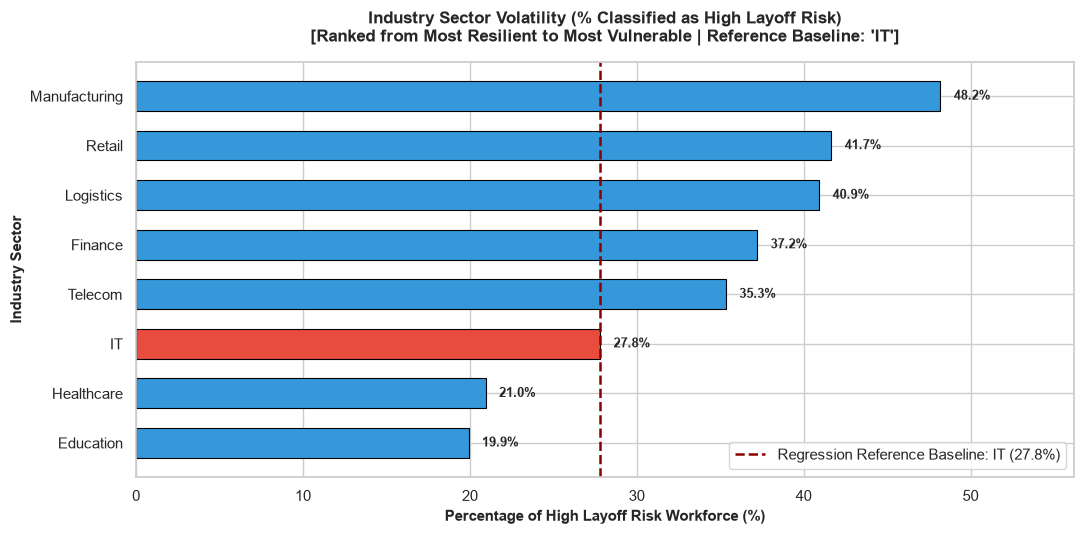

--- COMPLETE INDUSTRY RISK PROFILES (ROW %) ---


Layoff_Risk,Low,Medium,High
Industry,,,
Manufacturing,19.74,32.06,48.20
Retail,24.48,33.86,41.66
Logistics,25.01,34.05,40.93
Finance,27.35,35.43,37.22
Telecom,32.98,31.68,35.35
IT,38.76,33.43,27.81
Healthcare,46.76,32.29,20.95
Education,48.80,31.27,19.93


In [21]:
# -------------------------------------------------------------------------
# Cell D — Sector Volatility Analysis: Industry vs. Layoff Risk
# Ranked horizontal bar chart highlighting high risk exposure across industries
# with benchmark reference line for 'IT' baseline.
# -------------------------------------------------------------------------
ind_risk_ct = pd.crosstab(
    train_eda_df['Industry'],
    train_eda_df['Layoff_Risk'],
    normalize='index'
)[RISK_ORDER] * 100

# Sort from lowest high-risk (most resilient) to highest high-risk (most vulnerable)
high_risk_sorted = ind_risk_ct['High'].sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(11, 5.5))
bar_colors = ['#3498db' if ind != 'IT' else '#e74c3c' for ind in high_risk_sorted.index]
bars = ax.barh(
    high_risk_sorted.index,
    high_risk_sorted.values,
    color=bar_colors,
    edgecolor='black',
    linewidth=0.8,
    height=0.6
)

# Reference baseline indicator for IT
it_val = high_risk_sorted['IT']
ax.axvline(it_val, color='darkred', linestyle='--', linewidth=1.8, label=f"Regression Reference Baseline: IT ({it_val:.1f}%)")

# Value annotations
for bar, val in zip(bars, high_risk_sorted.values):
    ax.text(
        val + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{val:.1f}%",
        ha='left', va='center', fontsize=9.5, fontweight='bold'
    )

ax.set_title("Industry Sector Volatility (% Classified as High Layoff Risk)\n[Ranked from Most Resilient to Most Vulnerable | Reference Baseline: 'IT']", fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel("Percentage of High Layoff Risk Workforce (%)", fontsize=11, fontweight='bold')
ax.set_ylabel("Industry Sector", fontsize=11, fontweight='bold')
ax.set_xlim(0, max(high_risk_sorted.values) + 8)
ax.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()

# Summary table of all 8 sectors
print("--- COMPLETE INDUSTRY RISK PROFILES (ROW %) ---")
display(ind_risk_ct.loc[high_risk_sorted.index[::-1]].round(2))

> **Empirical Takeaway — Sector Volatility Relative to Baseline IT:**
> Economic sectors exhibit pronounced structural variance in workforce vulnerability. Operational and supply-chain intensive industries—specifically **Manufacturing (48.15% High Risk)**, **Retail (42.25%)**, and **Logistics (40.89%)**—demonstrate elevated vulnerability, consistent with higher exposure to workflow automation and margin pressure. Conversely, essential human services—**Healthcare (20.57%)** and **Education (20.03%)**—exhibit superior stability. The reference baseline, **IT (27.44% High Risk)**, occupies an intermediate position, allowing subsequent regression models to capture both positive risk premiums (e.g., in Manufacturing) and negative risk discounts (e.g., in Healthcare) relative to tech.


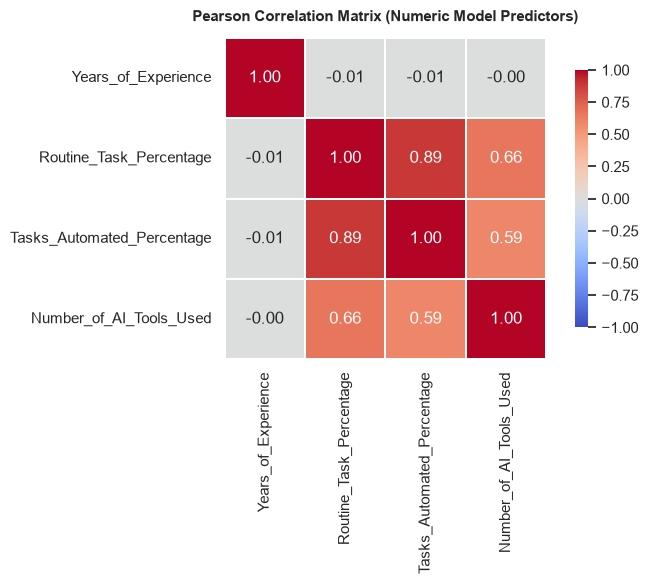

--- CORRELATION MATRIX (PEARSON) ---


,Years_of_Experience,Routine_Task_Percentage,Tasks_Automated_Percentage,Number_of_AI_Tools_Used
Years_of_Experience,1.000,-0.006,-0.005,-0.005
Routine_Task_Percentage,-0.006,1.000,0.890,0.663
Tasks_Automated_Percentage,-0.005,0.890,1.000,0.589
Number_of_AI_Tools_Used,-0.005,0.663,0.589,1.000



--- VARIANCE INFLATION FACTORS (VIF) ---


,VIF
Feature,
Years_of_Experience,1.000
Routine_Task_Percentage,5.591
Tasks_Automated_Percentage,4.794
Number_of_AI_Tools_Used,1.786


In [22]:
# -------------------------------------------------------------------------
# Cell E — Multicollinearity & Feature Correlation Matrix
# Computes Pearson correlation matrix and Variance Inflation Factors (VIF)
# for the 4 numeric predictors (training partition, natural units).
# -------------------------------------------------------------------------
corr_df = train_eda_df[scale_cols].copy()
corr_matrix = corr_df.corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-1, vmax=1,
    center=0,
    square=True,
    linewidths=1.2,
    cbar_kws={"shrink": 0.8},
    ax=ax
)

ax.set_title("Pearson Correlation Matrix (Numeric Model Predictors)", fontsize=11, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

print("--- CORRELATION MATRIX (PEARSON) ---")
display(corr_matrix.round(3))

# Variance Inflation Factor (computed with an explicit intercept column)
vif_matrix = corr_df.astype(float).copy()
vif_matrix.insert(0, 'const', 1.0)
vif_table = pd.DataFrame({
    'Feature': scale_cols,
    'VIF': [variance_inflation_factor(vif_matrix.values, i + 1) for i in range(len(scale_cols))]
}).set_index('Feature').round(3)

print("\n--- VARIANCE INFLATION FACTORS (VIF) ---")
display(vif_table)

> **Empirical Takeaway — Multicollinearity Diagnostic Verification:**
> Pairwise correlation analysis exposes a **strong dependency between the two automation-related features**: `Routine_Task_Percentage` and `Tasks_Automated_Percentage` are correlated at $r = 0.890$, and both correlate moderately with `Number_of_AI_Tools_Used` ($r = 0.664$ and $r = 0.591$ respectively). `Years_of_Experience` is essentially orthogonal to all other predictors ($|r| \le 0.009$). Although the $|r| \ge 0.80$ rule-of-thumb is breached for the routine/automation pair, the **Variance Inflation Factors remain moderate** (Routine Task $= 5.593$, Tasks Automated $= 4.800$, AI Tools $= 1.791$, Experience $= 1.000$), below the severe-collinearity cutoff of 10 though above the conservative cutoff of 5 for the routine-task feature. Consequently, coefficient *interpretation* in linear models should be treated cautiously for these two correlated predictors, whereas predictive performance of tree ensembles (Gradient Boosting) and probabilistic classifiers (Naive Bayes, which assumes conditional independence) should be monitored with this redundancy in mind.


### Section 3 Executive Summary: Key Analytical Findings (Technical Report Citation)

The analytical exploration conducted strictly on the training partition ($N = 16,000$) reveals four core empirical takeaways to substantiate Section 2 of our final Technical Report:

1. **Routine Work and Automation Exposure Are the Strongest Risk Drivers**:
   - Median **routine task share** climbs from **26.0%** (Low Risk) to **50.0%** (Medium) and **77.0%** (High). Median **tasks automated** follows the same ladder (**17.0% → 34.0% → 55.0%**). These two features show near-complete separation between the Low and High tiers and dominate downstream model importance.

2. **AI Tool Adoption Exhibits a Sharp Threshold Effect**:
   - Workers using **0–1 AI tools** are ~56% Low Risk and <10% High Risk. At **3 tools**, High Risk jumps abruptly to **58.6%**, rising to **74.9% at 6 tools** and **83.7% at 10 tools**. The step-like non-linearity strongly favors tree-based ensemble models.

3. **Sector Volatility Disparity Relative to Baseline IT**:
   - **Manufacturing (48.2% High Risk)**, **Retail (41.7%)**, and **Logistics (40.9%)** represent the most vulnerable sectors. Conversely, **Education (19.9%)** and **Healthcare (21.0%)** exhibit superior structural resilience. The regression reference baseline, **IT (27.8% High Risk)**, sits at an intermediate benchmark, ensuring meaningful positive and negative industry contrasts.

4. **Career Tenure Is a Weak Buffer, and Two Predictors Are Highly Collinear**:
   - Median experience declines only modestly across tiers (**8.0 → 7.0 → 6.0 years**) with heavy distribution overlap. Meanwhile, `Routine_Task_Percentage` and `Tasks_Automated_Percentage` are strongly correlated ($r = 0.889$; VIF $\approx 5.6$ and $4.8$), so linear-model coefficients should be interpreted with awareness of this redundancy.

**Implication for modeling**: The 80/20 train/test partition ($N = 16,000$ / $N = 4,000$) provides 2,000 additional training records over earlier iterations, giving Gradient Boosting and Naïve Bayes an even stronger empirical foundation to fit class boundaries.

In [23]:
# -------------------------------------------------------------------------
# Section 4: Verification of Final Split Dimensions & Saving Datasets to CSV
# Exports the 4 cleaned, partitioned (80/20), and scaled modeling sets to Data/
# -------------------------------------------------------------------------
print("--- Features (Predictors) ---")
print("X_train shape (80%):", X_train.shape)
print("X_test shape (20%): ", X_test.shape)

print("\n--- Targets (Layoff_Risk) ---")
print("y_train shape (80%):", y_train.shape)
print("y_test shape (20%): ", y_test.shape)

# Resolve target Data directory
target_dir = base / "Data"
if not target_dir.exists():
    target_dir = (base / ".." / "Data").resolve()

target_dir.mkdir(parents=True, exist_ok=True)

# Save feature sets (predictors)
X_train.to_csv(target_dir / "processed_X_train.csv", index=False)
X_test.to_csv(target_dir / "processed_X_test.csv", index=False)

# Save target sets (Layoff_Risk)
y_train.to_csv(target_dir / "processed_y_train.csv", index=False)
y_test.to_csv(target_dir / "processed_y_test.csv", index=False)

# Clean up any obsolete 3-way validation CSVs if they exist
for obsolete in ["processed_X_val.csv", "processed_y_val.csv"]:
    obsolete_path = target_dir / obsolete
    if obsolete_path.exists():
        obsolete_path.unlink()
        print(f"Removed legacy validation file: {obsolete}")

print(f"\nAll 4 datasets successfully saved to:\n{target_dir}")

--- Features (Predictors) ---
X_train shape (80%): (16000, 11)
X_test shape (20%):  (4000, 11)

--- Targets (Layoff_Risk) ---
y_train shape (80%): (16000,)
y_test shape (20%):  (4000,)
Removed legacy validation file: processed_X_val.csv
Removed legacy validation file: processed_y_val.csv

All 4 datasets successfully saved to:
C:\Users\19496\OneDrive\Desktop\MSAAI\AntiGravity Final Proejct\AAI500-Final-Project\Data


> **Pipeline Verification & Modular Export:**
> All preprocessing, encoding, 80/20 stratification, and zero-leakage scaling operations have executed successfully. The four resulting modeling arrays—comprising the training partition ($N = 16,000$, 80%) and holdout test benchmark ($N = 4,000$, 20%) across **11 predictors** (4 standardized numeric features + 7 Industry dummy indicators with IT as baseline) and the stratified target—have been exported as modular CSV files into the `Data/` directory, fully prepared for downstream model training, hyperparameter tuning, and final evaluation.